### Laboratorium 3 - zadania

In [1]:
import os

import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact, fixed
from scipy.ndimage import binary_fill_holes
import skimage as ski
from skimage.segmentation import slic, mark_boundaries
from skimage.color import label2rgb
from skimage.morphology import remove_small_objects
from skimage.segmentation import clear_border
from skimage.util import img_as_ubyte
from skimage.feature import peak_local_max

#### Zadanie 1

Dane są obrazy `tabby` i `caries` ([źródło](https://universe.roboflow.com/niu-workespeis/caries-xlrql/dataset/2)). Wykonaj dla nich segmentację przy użyciu algorytmu SLIC. Celem jest uzyskanie **jednolitych**  superpikseli, a więc zawierających tylko fragmenty obiektów lub tylko tła (a nie jednego i drugiego naraz). Przeanalizuj zachowanie algorytmu dla różnej liczby superpikseli i parametru sigma.

Zwróć uwagę, że wynikiem działania scikitowej implementacji SLIC - [`skimage.segmentation.slic`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.slic) - (podobnie jak wielu innych algorytmów klasyfikacyjnych) jest obraz typu `np.int64` przyporządkowujący każdemu pikselowi obrazu wejściowego indeks superpiksela. Takiej reprezentacji oczekuje też funkcja [`mark_boundaries`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.mark_boundaries).

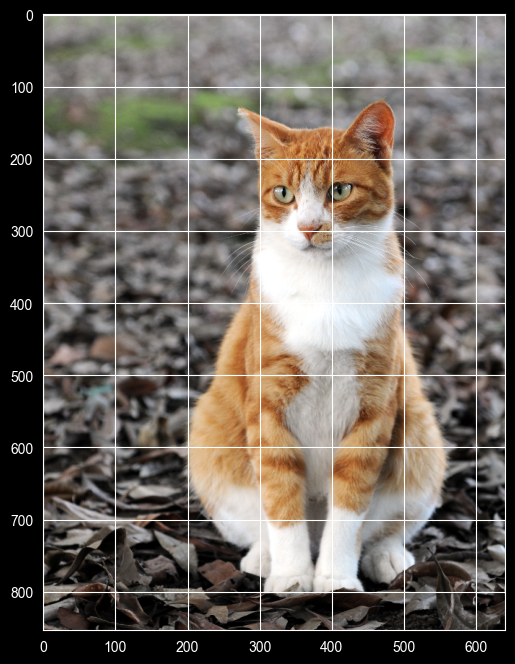

In [2]:
tabby_bgr = cv2.resize(cv2.imread('tabby.jpg'), dsize=None, fx=0.3, fy=0.3)
tabby = tabby_bgr[..., ::-1].copy()
plt.subplots(1,1,figsize=(8,8))[1].imshow(tabby);

In [3]:
def interactive_slic(image, n_segments, compactness, sigma, spacing_y=0.0, spacing_x=0.0):
    if spacing_y == 0 or spacing_x == 0:
        spacing = None
        spacing_title = ""
    else:
        spacing = (spacing_y, spacing_x)
        spacing_title = f", spacing=({spacing_y:.1f}, {spacing_x:.1f})"

    # RGB vs Grayscale
    channel_axis = -1 if image.ndim == 3 else None

    segments = slic(
        image,
        n_segments=n_segments,
        compactness=compactness,
        sigma=sigma,
        spacing=spacing,
        start_label=1,
        channel_axis=channel_axis
    )

    img_boundaries = mark_boundaries(image, segments, color=(1, 0, 0))
    avg_color_img = label2rgb(segments, image, kind='avg', bg_label=0)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6))

    ax[0].imshow(img_boundaries)
    ax[0].set_title(f"Krawędzie (n={n_segments}, comp={compactness:.1f}, $\sigma$={sigma}{spacing_title})")
    ax[0].axis('off')

    ax[1].imshow(avg_color_img)
    ax[1].set_title("Uśrednione kolory superpikseli")
    ax[1].axis('off')

    plt.tight_layout()
    plt.show()

<>:28: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:28: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\pauko\AppData\Local\Temp\ipykernel_29132\430359397.py:28: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  ax[0].set_title(f"Krawędzie (n={n_segments}, comp={compactness:.1f}, $\sigma$={sigma}{spacing_title})")


In [4]:
interact(
    interactive_slic,
    image=fixed(tabby),
    n_segments=widgets.IntSlider(min=20, max=1000, step=20, value=340, description='n_segments:'),
    compactness=widgets.FloatLogSlider(value=10, base=10, min=-2, max=2, step=1, description='compactness:'),
    sigma=widgets.FloatSlider(min=0.0, max=8.0, step=0.5, value=2.5, description='sigma:')
);

interactive(children=(IntSlider(value=340, description='n_segments:', max=1000, min=20, step=20), FloatLogSlid…

Wpływ parametrów:
- n_segments: przy małej wartości (ok. 50) superpiksele są duże i łączą kota z tłem. Przy dużej (ok. 400 i więcej) są jednolite, ale jest ich bardzo dużo. Wartość 340 to kompromis między jednolitością a liczbą segmentów.
- compactness: wartość 10 daje segmenty dopasowane do krawędzi, ale nie nadmiernie poszarpane. Przy 0.1 kształty są nieregularne, a przy 50 tworzy się sztywna siatka, która przecina kota.
- sigma: wartość 2.5 wygładza teksturę liści i szum, więc granice nie “łapią” każdego listka. Bez rozmycia (sigma = 0) segmentacja tła jest chaotyczna, a przy sigma = 5 rozmywają się krawędzie kota i cienkie struktury (wąsy, uszy).
- spacing: pozostawiono 0 (brak wag osi), ponieważ piksele obrazu są kwadratowe.

Wniosek: dla obrazu o wyraźnym, kolorowym obiekcie na teksturowanym tle najlepsze wyniki daje średnia liczba superpikseli (ok. 300-350), umiarkowana kompaktowość (ok. 10) i średnie wygładzanie (sigma ok. 2-3). SLIC wykorzystuje tu różnicę koloru między kotem a liśćmi, więc granice obiektu są odwzorowane dokładnie. Drobne niedoskonałości występują na jasnych łapach i uszach, gdzie kolor jest zbliżony do tła.

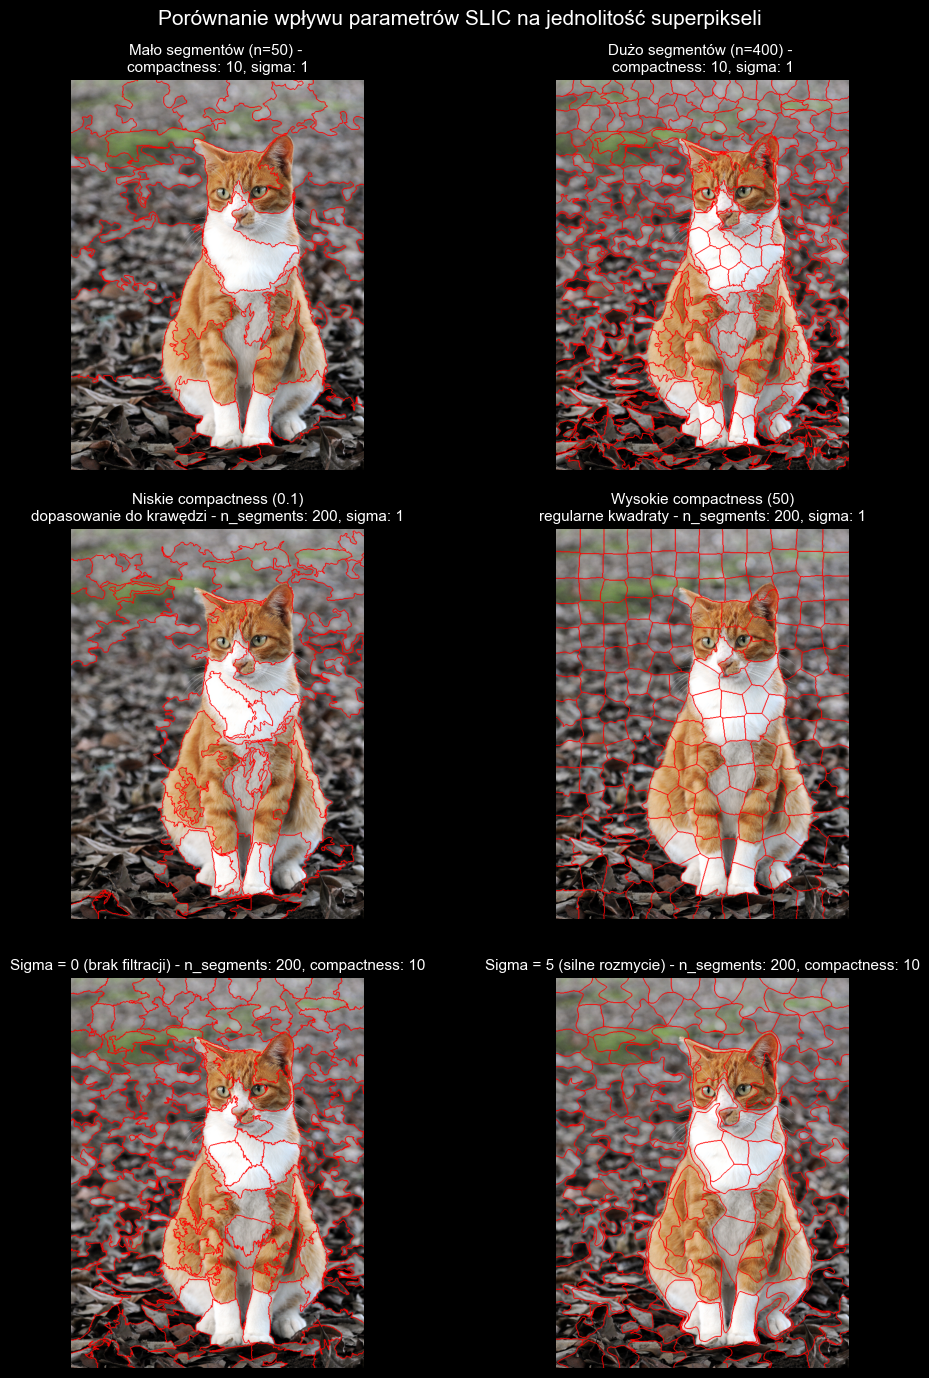

In [5]:
key_configs = [
    {"n_segments": 50,  "compactness": 10.0, "sigma": 1.0, "title": "Mało segmentów (n=50) - \ncompactness: 10, sigma: 1"},
    {"n_segments": 400, "compactness": 10.0, "sigma": 1.0, "title": "Dużo segmentów (n=400) - \ncompactness: 10, sigma: 1"},
    {"n_segments": 200, "compactness": 0.1,  "sigma": 1.0, "title": "Niskie compactness (0.1)\ndopasowanie do krawędzi - n_segments: 200, sigma: 1"},
    {"n_segments": 200, "compactness": 50.0, "sigma": 1.0, "title": "Wysokie compactness (50)\nregularne kwadraty - n_segments: 200, sigma: 1"},
    {"n_segments": 200, "compactness": 10.0, "sigma": 0.0, "title": "Sigma = 0 (brak filtracji) - n_segments: 200, compactness: 10"},
    {"n_segments": 200, "compactness": 10.0, "sigma": 5.0, "title": "Sigma = 5 (silne rozmycie) - n_segments: 200, compactness: 10"},
]

fig, axes = plt.subplots(3, 2, figsize=(10, 14))
axes = axes.ravel()

target_img = tabby

for idx, cfg in enumerate(key_configs):
    seg = slic(
        target_img,
        n_segments=cfg["n_segments"],
        compactness=cfg["compactness"],
        sigma=cfg["sigma"],
        start_label=1,
        channel_axis=-1
    )
    res = mark_boundaries(target_img, seg, color=(1, 0, 0))

    axes[idx].imshow(res)
    axes[idx].set_title(cfg["title"], fontsize=11, pad=6)
    axes[idx].axis('off')

plt.suptitle("Porównanie wpływu parametrów SLIC na jednolitość superpikseli", fontsize=15, y=0.99)

plt.subplots_adjust(wspace=0.02, hspace=0.15, left=0.02, right=0.98, top=0.94, bottom=0.02)
plt.show()

### 1. Liczba superpikseli: n=50 vs n=400

Parametr `n_segments` steruje kompromisem między jednolitością superpikseli a zwięzłością reprezentacji. Przy n=50 obraz dzieli się na kilka dużych obszarów, które często łączą różne struktury: na korpusie kota pomarańczowe pasy zlewają się z białym futrem, a w tle jeden segment obejmuje liście o różnej jasności i zieloną trawę, więc ich średni kolor jest mieszaniną i jednolitość nie zostaje osiągnięta. Przy n=400 superpiksele są mniejsze i rzadziej obejmują kilka obiektów, ale reprezentacja staje się nadmiarowa, bo np. jednolite białe futro na piersi jest pocięte na wiele wielokątów. Dla obrazu `tabby` rozsądnym kompromisem jest n rzędu 300-350, a ostateczny efekt zależy też od `compactness` i `sigma`.

### 2. Zwartość: compactness 0.1 vs 50

Parametr `compactness` ustala, jak bardzo liczy się położenie piksela względem jego koloru. Przy 0.1 dominuje kolor: granice dokładnie śledzą krawędzie i pasy futra, ale superpiksele są poszarpane i wydłużone, a w tle łączą odległe liście o podobnej barwie. Przy 50 dominuje położenie: powstaje regularna siatka komórek, która zachowuje kontur kota dzięki wysokiemu kontrastowi, ale ignoruje pasy futra i słabsze krawędzie (np. jasne łapy na jasnych liściach), przez co jednolitość spada. Dla jednolitych superpikseli najlepsza jest wartość pośrednia, ok. 10, a dla `caries` o niskim kontraście znacznie mniejsza.

### 3. Wygładzanie: sigma=0 vs sigma=5

Parametr `sigma` ustala siłę rozmycia gaussowskiego przed segmentacją, czyli to, które szczegóły wpłyną na podział. Przy sigma=0 algorytm reaguje na każdy drobny kontrast: wnętrze kota jest postrzępione i rozdrobnione, a tło chaotyczne, bo każdy liść i cień staje się osobną strukturą. Przy sigma=5 tekstura i szum znikają, a segmenty są duże i gładkie, ale cienkie elementy (uszy, łapy, dolny kontur) są zaokrąglone, a granica miejscami wychodzi poza kota, bo rozmyte krawędzie są trudniejsze do zlokalizowania. Najlepszy jest kompromis rzędu 2-3 (w konfiguracji interaktywnej sigma=2.5), który tłumi teksturę tła i zachowuje kontur obiektu.

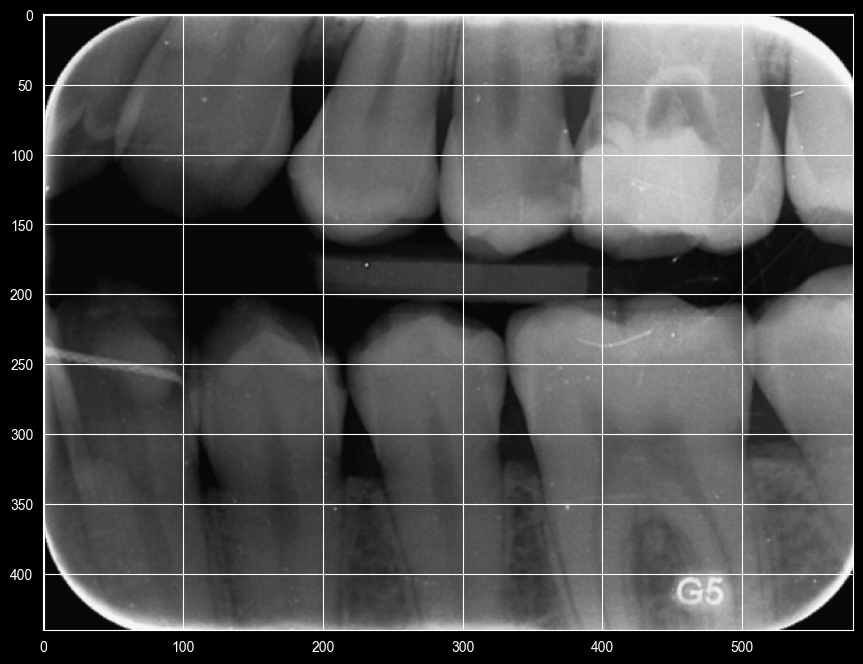

In [6]:
caries = cv2.imread('roboflow-caries-117.jpg')[..., 0]
plt.subplots(1,1,figsize=(12,8))[1].imshow(caries, cmap='gray');

In [7]:
interact(
    interactive_slic,
    image=fixed(caries),
    n_segments=widgets.IntSlider(min=20, max=1000, step=20, value=480, description='n_segments:'),
    compactness=widgets.SelectionSlider(
        options=[0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 1.0, 10.0, 50.0],
        value=0.05,
        description='compactness:'
    ),
    sigma=widgets.FloatSlider(min=0.0, max=8.0, step=0.5, value=1.0, description='sigma:'),
    spacing_y=widgets.FloatSlider(min=0.0, max=5.0, step=0.2, value=0.0, description='spacing Y:'),
    spacing_x=widgets.FloatSlider(min=0.0, max=5.0, step=0.2, value=0.0, description='spacing X:')
);

interactive(children=(IntSlider(value=480, description='n_segments:', max=1000, min=20, step=20), SelectionSli…

Wpływ parametrów:

- n_segments: przy małej wartości (ok. 50) superpiksele są duże i obejmują jednocześnie zęby, kość i fragmenty szczeliny. Przy dużej (ok. 500) są jednolite, ale liczne. Wartość 480 to kompromis, bo drobne struktury (wypełnienie, ubytek) mają własne segmenty.
- compactness: obraz jest jednokanałowy i niskokontrastowy, więc różnice jasności są małe i potrzebne są małe wartości (0.05-0.1). Wartości rzędu 10-50, dobre dla tabby, dają tu sztywną siatkę ignorującą krawędzie zębów.
- sigma: wartość 1.0 tłumi szum i ziarno kości, a jednocześnie zachowuje krawędzie szkliwa. Bez rozmycia segmentacja kości jest chaotyczna, a przy dużej sigma rozmywają się wąskie struktury (granica szkliwa, ubytek).
spacing: pozostawiono 0, ponieważ piksele obrazu są kwadratowe.

Wniosek: dla niskokontrastowego, zaszumionego obrazu RTG najlepsze wyniki daje duża liczba superpikseli (ok. 480), bardzo mała kompaktowość (ok. 0.05) i lekkie wygładzanie (sigma ok. 1). Granice zębów i wypełnienia są odwzorowane dokładnie, a słabiej wypadają obszary o zbliżonej jasności (korzenie i kość) oraz płaskie tło, które jest dzielone nadmiarowo.

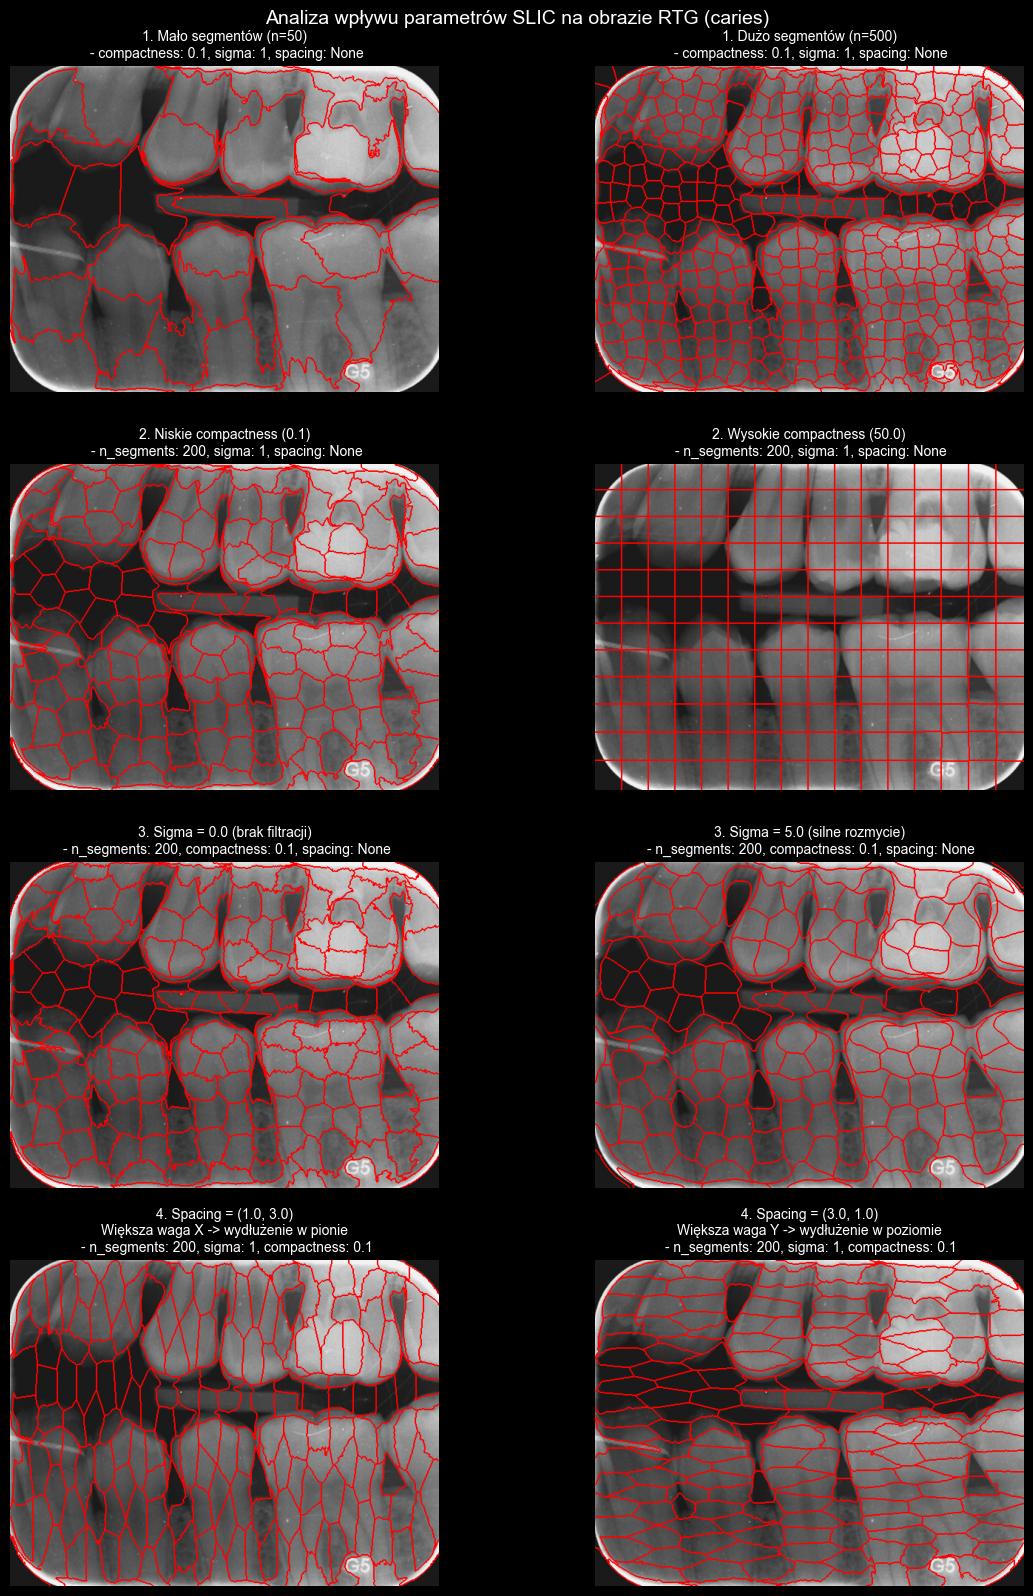

In [8]:
key_configs = [
    {"n_segments": 50,  "compactness": 0.1, "sigma": 1.0, "spacing": None,       "title": "1. Mało segmentów (n=50)\n - compactness: 0.1, sigma: 1, spacing: None"},
    {"n_segments": 500, "compactness": 0.1, "sigma": 1.0, "spacing": None,       "title": "1. Dużo segmentów (n=500)\n - compactness: 0.1, sigma: 1, spacing: None"},

    {"n_segments": 200, "compactness": 0.1,  "sigma": 1.0, "spacing": None,       "title": "2. Niskie compactness (0.1)\n - n_segments: 200, sigma: 1, spacing: None"},
    {"n_segments": 200, "compactness": 50.0, "sigma": 1.0, "spacing": None,       "title": "2. Wysokie compactness (50.0)\n - n_segments: 200, sigma: 1, spacing: None"},

    {"n_segments": 200, "compactness": 0.1, "sigma": 0.0, "spacing": None,       "title": "3. Sigma = 0.0 (brak filtracji)\n - n_segments: 200, compactness: 0.1, spacing: None"},
    {"n_segments": 200, "compactness": 0.1, "sigma": 5.0, "spacing": None,       "title": "3. Sigma = 5.0 (silne rozmycie)\n - n_segments: 200, compactness: 0.1, spacing: None"},

    {"n_segments": 200, "compactness": 0.1, "sigma": 1.0, "spacing": (1.0, 3.0), "title": "4. Spacing = (1.0, 3.0)\nWiększa waga X -> wydłużenie w pionie\n - n_segments: 200, sigma: 1, compactness: 0.1"},
    {"n_segments": 200, "compactness": 0.1, "sigma": 1.0, "spacing": (3.0, 1.0), "title": "4. Spacing = (3.0, 1.0)\nWiększa waga Y -> wydłużenie w poziomie\n - n_segments: 200, sigma: 1, compactness: 0.1"},
]

fig, axes = plt.subplots(4, 2, figsize=(12, 16))
axes = axes.ravel()

channel_axis = -1 if caries.ndim == 3 else None

for idx, cfg in enumerate(key_configs):
    seg = slic(
        caries,
        n_segments=cfg["n_segments"],
        compactness=cfg["compactness"],
        sigma=cfg["sigma"],
        spacing=cfg["spacing"],
        start_label=1,
        channel_axis=channel_axis
    )
    res = mark_boundaries(caries, seg, color=(1, 0, 0))

    axes[idx].imshow(res)
    axes[idx].set_title(cfg["title"], fontsize=10, pad=6)
    axes[idx].axis('off')

plt.suptitle("Analiza wpływu parametrów SLIC na obrazie RTG (caries)", fontsize=14, y=0.995)
plt.subplots_adjust(wspace=0.03, hspace=0.22, left=0.02, right=0.98, top=0.96, bottom=0.01)
plt.show()

#### 1. Liczba superpikseli: n=50 vs n=500

Przy n=50 obraz dzieli się na kilkadziesiąt dużych obszarów, które łączą różne struktury: korony zębów zlewają się z korzeniami i kością, a jasne wypełnienie w zębie po prawej u góry jest częścią jednego dużego segmentu razem z otaczającą tkanką. Przy n=500 wypełnienie, ubytek i poszczególne korony mają własne, jednolite superpiksele, ale reprezentacja jest nadmiarowa: płaskie, ciemne tło po lewej i szczelina między łukami są dzielone na dziesiątki komórek, mimo że są jednolite. Dla caries rozsądne jest n rzędu 300-500, bo drobne struktury diagnostyczne są małe i przy mniejszym n po prostu giną.

#### 2. Zwartość: compactness 0.1 vs 50

Przy 0.1 granice dobrze podążają za krawędziami zębów, wypełnieniem i przestrzeniami międzyzębowymi, a kształty pozostają dość zwarte, bo obraz ma wąski zakres jasności. Przy 50 powstaje sztywna, prostokątna siatka, która całkowicie ignoruje anatomię i przecina zęby, szczelinę i kość. To znacznie silniejszy efekt niż dla tabby, ponieważ różnice jasności na RTG są małe i już niewielka waga odległości przestrzennej dominuje nad kolorem. Wniosek: dla obrazów szarych o niskim kontraście compactness musi być bardzo małe (0.05-0.1).

#### 3. Wygładzanie: sigma=0 vs sigma=5

Przy sigma=0 algorytm reaguje na szum i ziarno kości: granice w obrębie zębów i kości są postrzępione, a wypełnienie jest dzielone na nieregularne kawałki. Przy sigma=5 segmenty są gładkie i regularniejsze, ale krawędzie zaokrąglają się, a wąskie struktury (ciemny ubytek, cienka granica szkliwa) tracą precyzję i są łączone z otoczeniem. Dobry kompromis to sigma ok. 1, które tłumi szum, a zachowuje kontury szkliwa.

#### 4. Spacing: (1, 3) vs (3, 1)

Parametr spacing zmienia wagi osi przy liczeniu odległości przestrzennej, więc deformuje kształt superpikseli. Przy (1, 3) segmenty są wydłużone w pionie, a przy (3, 1) w poziomie. Dla zdjęcia z kwadratowymi pikselami nie ma uzasadnienia fizycznego, ale pokazuje on, że kształt segmentów można celowo sterować. Wydłużenie pionowe pasuje do osi zębów i korzeni, natomiast poziome przecina je w poprzek i pogarsza jednolitość. Dla caries spacing zostaje więc na wartości domyślnej.

#### Zadanie 2

Wykonaj segmentację wododziałową dla obrazów `tabby` i `caries` za pomocą funkcji [`cv2.watershed`](https://docs.opencv.org/4.x/d3/d47/group__imgproc__segmentation.html#ga3267243e4d3f95165d55a618c65ac6e1). Implementacja OpenCV przyjmuje dwa argumenty: obraz wejściowy (8-bit, 3 kanały) i obraz wyjściowy (32-bit, 1 kanał).

Uwaga: obraz wyjściowy musi zawierać oznaczenia początkowe segmentów (_markery_) - to znaczy, że musisz zacząć od przygotowania macierzy markerów. Poprawnie przygotowana macierz zawiera $N$ markerów, tj. pikseli oznaczonych liczbami całkowitymi od 1 do $N$, a wartość pozostałych pikseli wynosi 0. Piksele zerowe zostaną przyporządkowane do grup dookoła markerów.

Sugerowane metody przygotowania markerów (wybierz dwie i porównaj):
* równomierna siatka
* lokalne minima jasności
* manualnie wybrane centra (_segmentacja interaktywna_)

In [9]:
def prepare_watershed_markers(
    image,
    method='distance',       # 'distance', 'grid', 'local_minima', 'manual'
    use_clahe=False,
    blur_ksize=5,
    alpha=0.3,
    min_size=5000,
    min_marker_size=1000,
    clear_edges=False,
    dilate_iter=5,
    grid_step=40,            # 'grid': odstęp między markerami [px]
    min_distance=15,         # 'local_minima': min. odległość między minimami [px]
    marker_radius=3,         # 'grid', 'local_minima', 'manual': promień markera [px]
    manual_points=None,      # 'manual': lista segmentów, każdy = lista punktów (x, y)
):
    steps = {}

    if image.ndim == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray = image.copy()
    steps['1. Gray'] = gray.copy()

    if use_clahe:
        gray_float = ski.util.img_as_float(gray)
        gray_enhanced = ski.exposure.equalize_adapthist(gray_float, clip_limit=0.03)
        gray = img_as_ubyte(gray_enhanced)
        steps['2. CLAHE'] = gray.copy()

    if blur_ksize > 1:
        gray_blur = cv2.medianBlur(gray, ksize=blur_ksize)
    else:
        gray_blur = gray.copy()
    steps['3. Blur'] = gray_blur.copy()

    h, w = gray.shape
    sure_fg, sure_bg, unknown = None, None, None

    if method == 'distance':
        _, binary = cv2.threshold(gray_blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        steps['4. Otsu Binary'] = binary.copy()

        kernel = np.ones((3, 3), np.uint8)
        opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=2)
        steps['5. Opening'] = opening.copy()

        mask_bool = opening > 0
        if min_size > 0:
            mask_bool = remove_small_objects(mask_bool, min_size=min_size)

        mask_filled = binary_fill_holes(mask_bool)
        if clear_edges:
            mask_filled = clear_border(mask_filled)

        mask_ubyte = img_as_ubyte(mask_filled)
        steps['6. Maska (Filled)'] = mask_ubyte.copy()

        dist_transform = cv2.distanceTransform(mask_ubyte, cv2.DIST_L2, 5)
        steps['7. Dist Transform'] = dist_transform.copy()

        _, sure_fg = cv2.threshold(dist_transform, alpha * dist_transform.max(), 255, 0)
        sure_fg = np.uint8(sure_fg)

        if min_marker_size > 0:
            sure_fg_bool = remove_small_objects(sure_fg > 0, min_size=min_marker_size)
            sure_fg = img_as_ubyte(sure_fg_bool)
        steps['8. Sure FG'] = sure_fg.copy()

        sure_bg = cv2.dilate(mask_ubyte, kernel, iterations=dilate_iter)
        steps['9. Sure BG'] = sure_bg.copy()

        unknown = cv2.subtract(sure_bg, sure_fg)
        steps['10. Unknown'] = unknown.copy()

        _, markers = cv2.connectedComponents(sure_fg)
        markers = markers + 1
        markers[unknown == 255] = 0
        steps['11. Markers'] = markers.copy()

    elif method == 'grid':
        markers = np.zeros((h, w), dtype=np.int32)
        r = min(marker_radius, max(grid_step // 2 - 1, 0))

        label = 1
        for y in range(grid_step // 2, h, grid_step):
            for x in range(grid_step // 2, w, grid_step):
                cv2.circle(markers, (int(x), int(y)), int(r), int(label), -1)
                label += 1

        steps['11. Markers (Grid)'] = markers.copy()

    elif method == 'local_minima':
        sigma = max(blur_ksize / 3.0, 1.0)
        smooth = ski.filters.gaussian(gray, sigma=sigma, preserve_range=True)
        steps['3b. Gaussian (minima)'] = smooth.astype(np.uint8)

        grad = ski.filters.sobel(smooth)
        steps['3c. Gradient (minima)'] = (255 * grad / grad.max()).astype(np.uint8)

        coords = peak_local_max(
            -grad,
            min_distance=min_distance,
            exclude_border=False,
        )

        markers = np.zeros((h, w), dtype=np.int32)
        for idx, (y, x) in enumerate(coords, start=1):
            cv2.circle(markers, (int(x), int(y)), int(marker_radius), int(idx), -1)

        steps['11. Markers (Minima)'] = markers.copy()

    elif method == 'manual':
        if not manual_points:
            raise ValueError(
                "Dla method='manual' podaj manual_points, np. "
                "[[(x1, y1), (x2, y2)], [(x3, y3)]] - każdy element listy to jeden segment."
            )

        markers = np.zeros((h, w), dtype=np.int32)
        for label, points in enumerate(manual_points, start=1):
            for (x, y) in points:
                cv2.circle(markers, (int(x), int(y)), int(marker_radius), int(label), -1)

        steps['11. Markers (Manual)'] = markers.copy()

    else:
        raise ValueError(f"Nieznana metoda: {method}")

    return sure_fg, sure_bg, unknown, markers, steps

def color_gradient(image, grad_ksize=3, blur_ksize=5):
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    lab = cv2.GaussianBlur(lab, (blur_ksize, blur_ksize), 0)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (grad_ksize, grad_ksize))
    grads = [cv2.morphologyEx(lab[..., c], cv2.MORPH_GRADIENT, kernel) for c in range(3)]
    return np.max(grads, axis=0)

def gray_gradient(gray, grad_ksize=3, blur_ksize=5):
    smooth = cv2.GaussianBlur(gray, (blur_ksize, blur_ksize), 0)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (grad_ksize, grad_ksize))
    return cv2.morphologyEx(smooth, cv2.MORPH_GRADIENT, kernel)

def run_watershed(image, markers, use_gradient=True, grad_ksize=3, blur_ksize=5):
    if image.ndim == 3:
        img_color = image.copy()
    else:
        img_color = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

    if use_gradient:
        if image.ndim == 3:
            grad = color_gradient(image, grad_ksize, blur_ksize)
        else:
            grad = gray_gradient(image, grad_ksize, blur_ksize)
        ws_input = cv2.cvtColor(grad, cv2.COLOR_GRAY2BGR)
    else:
        ws_input = img_color

    markers_ws = markers.astype(np.int32).copy()
    labels = cv2.watershed(ws_input, markers_ws)

    overlay = img_color.copy()
    overlay[labels == -1] = [0, 0, 255]
    return labels, overlay

In [10]:
def _to_rgb(image):
    if image.ndim == 2:
        return cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

def rel_points(image, segments):
    h, w = image.shape[:2]
    return [[(int(fx * w), int(fy * h)) for fx, fy in seg] for seg in segments]

def markers_overlay(img_rgb, markers, grow=2):
    shown = ski.morphology.dilation(markers, ski.morphology.disk(grow))
    colored = label2rgb(shown, image=img_rgb, bg_label=0, alpha=1.0,
                        colors=plt.cm.tab10.colors if markers.max() <= 10 else None)
    out = img_rgb.copy().astype(float) / 255.0
    mask = shown > 0
    out[mask] = colored[mask]
    return out


def compare_marker_methods(image, title, configs, use_gradient=True):
    img_rgb = _to_rgb(image)
    n = len(configs)
    fig, axes = plt.subplots(n, 3, figsize=(14, 4.8 * n), squeeze=False,
                             constrained_layout=True)

    for row, (name, params) in enumerate(configs):
        _, _, _, markers, _ = prepare_watershed_markers(image, **params)
        labels, overlay = run_watershed(image, markers, use_gradient=use_gradient)

        n_markers = int(markers.max())
        n_segments = len(np.unique(labels[labels > 0]))

        seg = labels.copy()
        seg[seg < 0] = 0
        seg_rgb = label2rgb(seg, image=img_rgb, kind='avg', bg_label=0)

        axes[row, 0].imshow(markers_overlay(img_rgb, markers))
        axes[row, 0].set_title(f"{name}: markery ({n_markers})", fontsize=11)

        axes[row, 1].imshow(seg_rgb)
        axes[row, 1].set_title(f"{name}: segmenty ({n_segments})", fontsize=11)

        axes[row, 2].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        axes[row, 2].set_title(f"{name}: granice", fontsize=11)

        for ax in axes[row]:
            ax.axis('off')

    fig.suptitle(f"Porównanie metod markerów: {title}", fontsize=14)
    plt.show()

C:\Users\pauko\AppData\Local\Temp\ipykernel_29132\1085473305.py:49: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask_bool = remove_small_objects(mask_bool, min_size=min_size)
C:\Users\pauko\AppData\Local\Temp\ipykernel_29132\1085473305.py:65: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  sure_fg_bool = remove_s

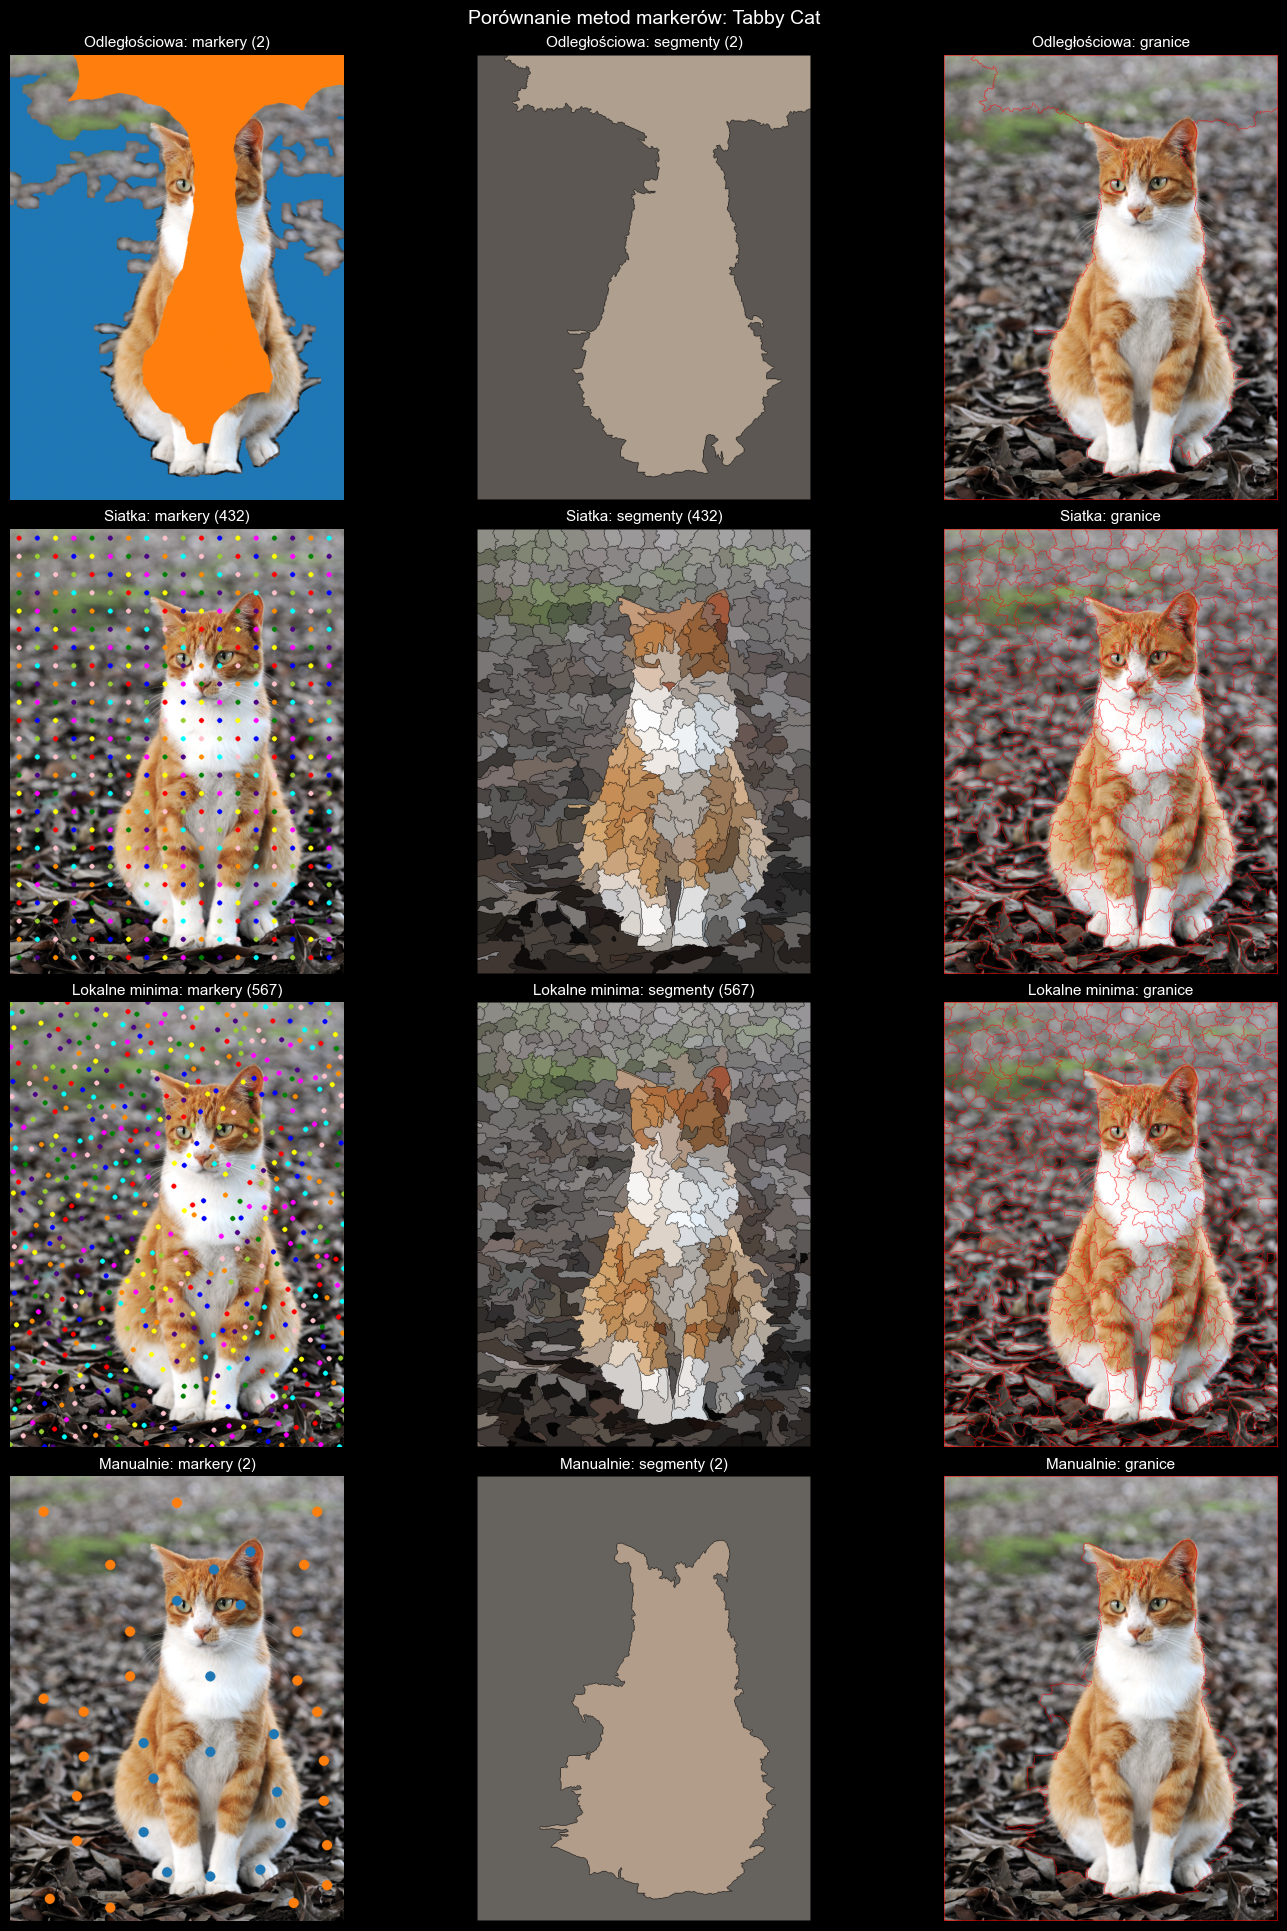

In [11]:
tabby_manual = rel_points(tabby_bgr, [
    [(0.61, 0.21), (0.50, 0.28), (0.69, 0.29), (0.60, 0.45), (0.60, 0.62),
     (0.40, 0.60), (0.79, 0.58), (0.43, 0.68), (0.80, 0.71), (0.40, 0.80),
     (0.81, 0.78), (0.47, 0.89), (0.60, 0.90), (0.75, 0.885),
     (0.72, 0.17)],

    [(0.10, 0.08), (0.50, 0.06), (0.92, 0.08),        # góra
     (0.30, 0.20), (0.88, 0.20),                      # obok głowy
     (0.36, 0.35), (0.86, 0.35),                      # obok szyi
     (0.36, 0.45), (0.86, 0.46),                      # obok piersi
     (0.10, 0.50), (0.22, 0.53), (0.92, 0.53),        # obok boków (tu był wyciek)
     (0.22, 0.63), (0.94, 0.64),
     (0.20, 0.72), (0.94, 0.73),
     (0.20, 0.82), (0.95, 0.83),                      # obok zadu
     (0.12, 0.95), (0.30, 0.97), (0.85, 0.96), (0.95, 0.92)],  # dół
])

compare_marker_methods(tabby_bgr, "Tabby Cat", [
    ("Odległościowa",  dict(method='distance', blur_ksize=9, alpha=0.3, min_size=5000, min_marker_size=1000)),
    ("Siatka",         dict(method='grid', grid_step=35, marker_radius=3)),
    ("Lokalne minima", dict(method='local_minima', blur_ksize=9, min_distance=15, marker_radius=3)),
    ("Manualnie",      dict(method='manual', manual_points=tabby_manual, marker_radius=8)),
])

#### 1. Odległościowa (2 markery, 2 segmenty)
- Wynik jest poprawny w dolnej części obrazu, ale z jednym błędem w górnej. Z THRESH_BINARY maska obejmuje jasne piksele, czyli białe i pomarańczowe futro kota, a ciemne liście odpadają. Linia graniczna (prawy panel) wiernie obrysowuje sylwetkę kota: uszy, boki, łapy. To zgadza się z założeniem, że obiekt jest jaśniejszy od tła.
- Zalety: w pełni automatyczna, bez ręcznych punktów, zwięzły wynik, a obrys sylwetki jest dokładny. Działa tu, bo kot jest wyraźnie jaśniejszy od większości tła.
- Wady: zależy od jednego globalnego progu Otsu i od założenia o polaryzacji (obiekt jaśniejszy lub ciemniejszy od tła). Nie rozróżnia „jasnego obiektu” od „jasnego fragmentu tła”, więc wszystko, co jest jasne i połączone z obiektem, trafia do rdzenia. To zadziałało tu przypadkiem, bo kot jest jasny.

#### 2. Siatka (432 markery)

- Segmenty są drobne i regularnie rozmieszczone. Kontur kota jest w dużej mierze odwzorowany, bo gradient na krawędzi sylwetki jest silny, ale wnętrze kota i tło są pocięte na setki małych kawałków. Segmenty w tle są chaotyczne, bo tekstura liści daje mnóstwo grzbietów.

- Zalety: najprostsza, deterministyczna, nie wymaga żadnej wiedzy o obrazie ani parametrów zależnych od jasności. Nigdy nie zawodzi całkowicie, bo każdy obszar dostaje jakiś marker. Daje gwarantowaną, równomierną gęstość segmentów.

- Wady: marker nie wie, czy leży na kocie, czy na tle, więc o liczbie i rozmiarze segmentów decyduje tylko grid_step, a nie treść obrazu. Jednorodne obszary (białe futro) są cięte bez potrzeby, a drobne struktury mogą zostać bez markera. Jednolitość wymaga gęstej siatki, a wtedy segmentów jest za dużo.

#### 3. Lokalne minima (567 markerów)

- Markery są rozłożone nierówno: bardzo gęsto w tle (zwłaszcza u góry, gdzie jest rozmyta trawa i liście) i rzadziej na kocie. Kontur kota jest dobrze zachowany, ale wnętrze jest rozdrobnione, a tło przesegmentowane (567 segmentów to więcej niż przy siatce).

- Zalety: markery lądują w jednorodnych obszarach, więc segmenty lepiej odpowiadają strukturze obrazu niż przy siatce, a granice trzymają się krawędzi. Działa niezależnie od tego, czy obiekt jest jaśniejszy, czy ciemniejszy od tła.

- Wady: liczba markerów jest bardzo wrażliwa na szum i teksturę. Przy min_distance=15 i blur_ksize=9 tekstura liści nadal generuje setki minimów, więc wynik jest przesegmentowany. Metoda nie wie, co jest obiektem, więc nie scala kota w jeden segment. Poprawa: większe blur_ksize (np. 15) i min_distance (25-30), co zmniejszy liczbę segmentów do kilkudziesięciu.

#### 4. Manualna (2 segmenty)

- Najlepszy wynik pod względem celu. Kot jest wyodrębniony jako jeden spójny segment, a tło jako drugi, z dokładnym konturem sylwetki, uszami i łapami. Widać drobne niedoskonałości: lekki wyciek po lewej stronie przy dolnej łapie (wypustka w stronę tła) oraz lekko postrzępiona granica przy prawym uchu.

- Zalety: pełna kontrola nad semantyką (wiemy, że to kot i tło), minimalna liczba segmentów, najczystszy wynik. Wystarczy kilkanaście punktów, żeby uzyskać segmentację zbliżoną do maski obiektu.

- Wady: wymaga udziału człowieka i wiedzy o obrazie, nie skaluje się na duże zbiory. Jakość zależy od rozmieszczenia punktów, szczególnie markerów tła przy samej granicy obiektu. Nie odkrywa nowych struktur, tylko dzieli obraz na to, co użytkownik wskaże. Nie ma tu też automatycznej kontroli: marker w złym miejscu daje zły segment.

#### Wnioski
- Jakość segmentacji watershed zależy głównie od markerów, a nie od samego algorytmu. Ten sam gradient dał cztery skrajnie różne wyniki.
- Metody w pełni automatyczne wymagają dopasowania do obrazu. Odległościowa zawiodła przez błędne założenie o jasności, a siatka i lokalne minima przesegmentowały obraz przez teksturę tła. Żadna nie rozpoznaje, co jest kotem.
- Dla obrazu z teksturowanym tłem i wyraźnym obiektem najlepsza jest segmentacja interaktywna. Daje mało segmentów i dokładny kontur, kosztem pracy człowieka.
- Liczba segmentów to kompromis, jak przy n_segments w SLIC: siatka i minima oferują jednolitość kosztem zwięzłości, a manualna odwrotnie. Warto zaznaczyć w sprawozdaniu, że 432 i 567 segmentów to wyniki bez strojenia parametrów, a po zwiększeniu grid_step i min_distance liczby spadną do setki lub mniej.
- Gradient kolorowy (Lab) pomógł wszystkim metodom z markerami, bo pomarańczowy kot i brązowe liście są podobne jasnością, ale różnią się barwą.

C:\Users\pauko\AppData\Local\Temp\ipykernel_29132\1085473305.py:49: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask_bool = remove_small_objects(mask_bool, min_size=min_size)
C:\Users\pauko\AppData\Local\Temp\ipykernel_29132\1085473305.py:65: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  sure_fg_bool = remove_s

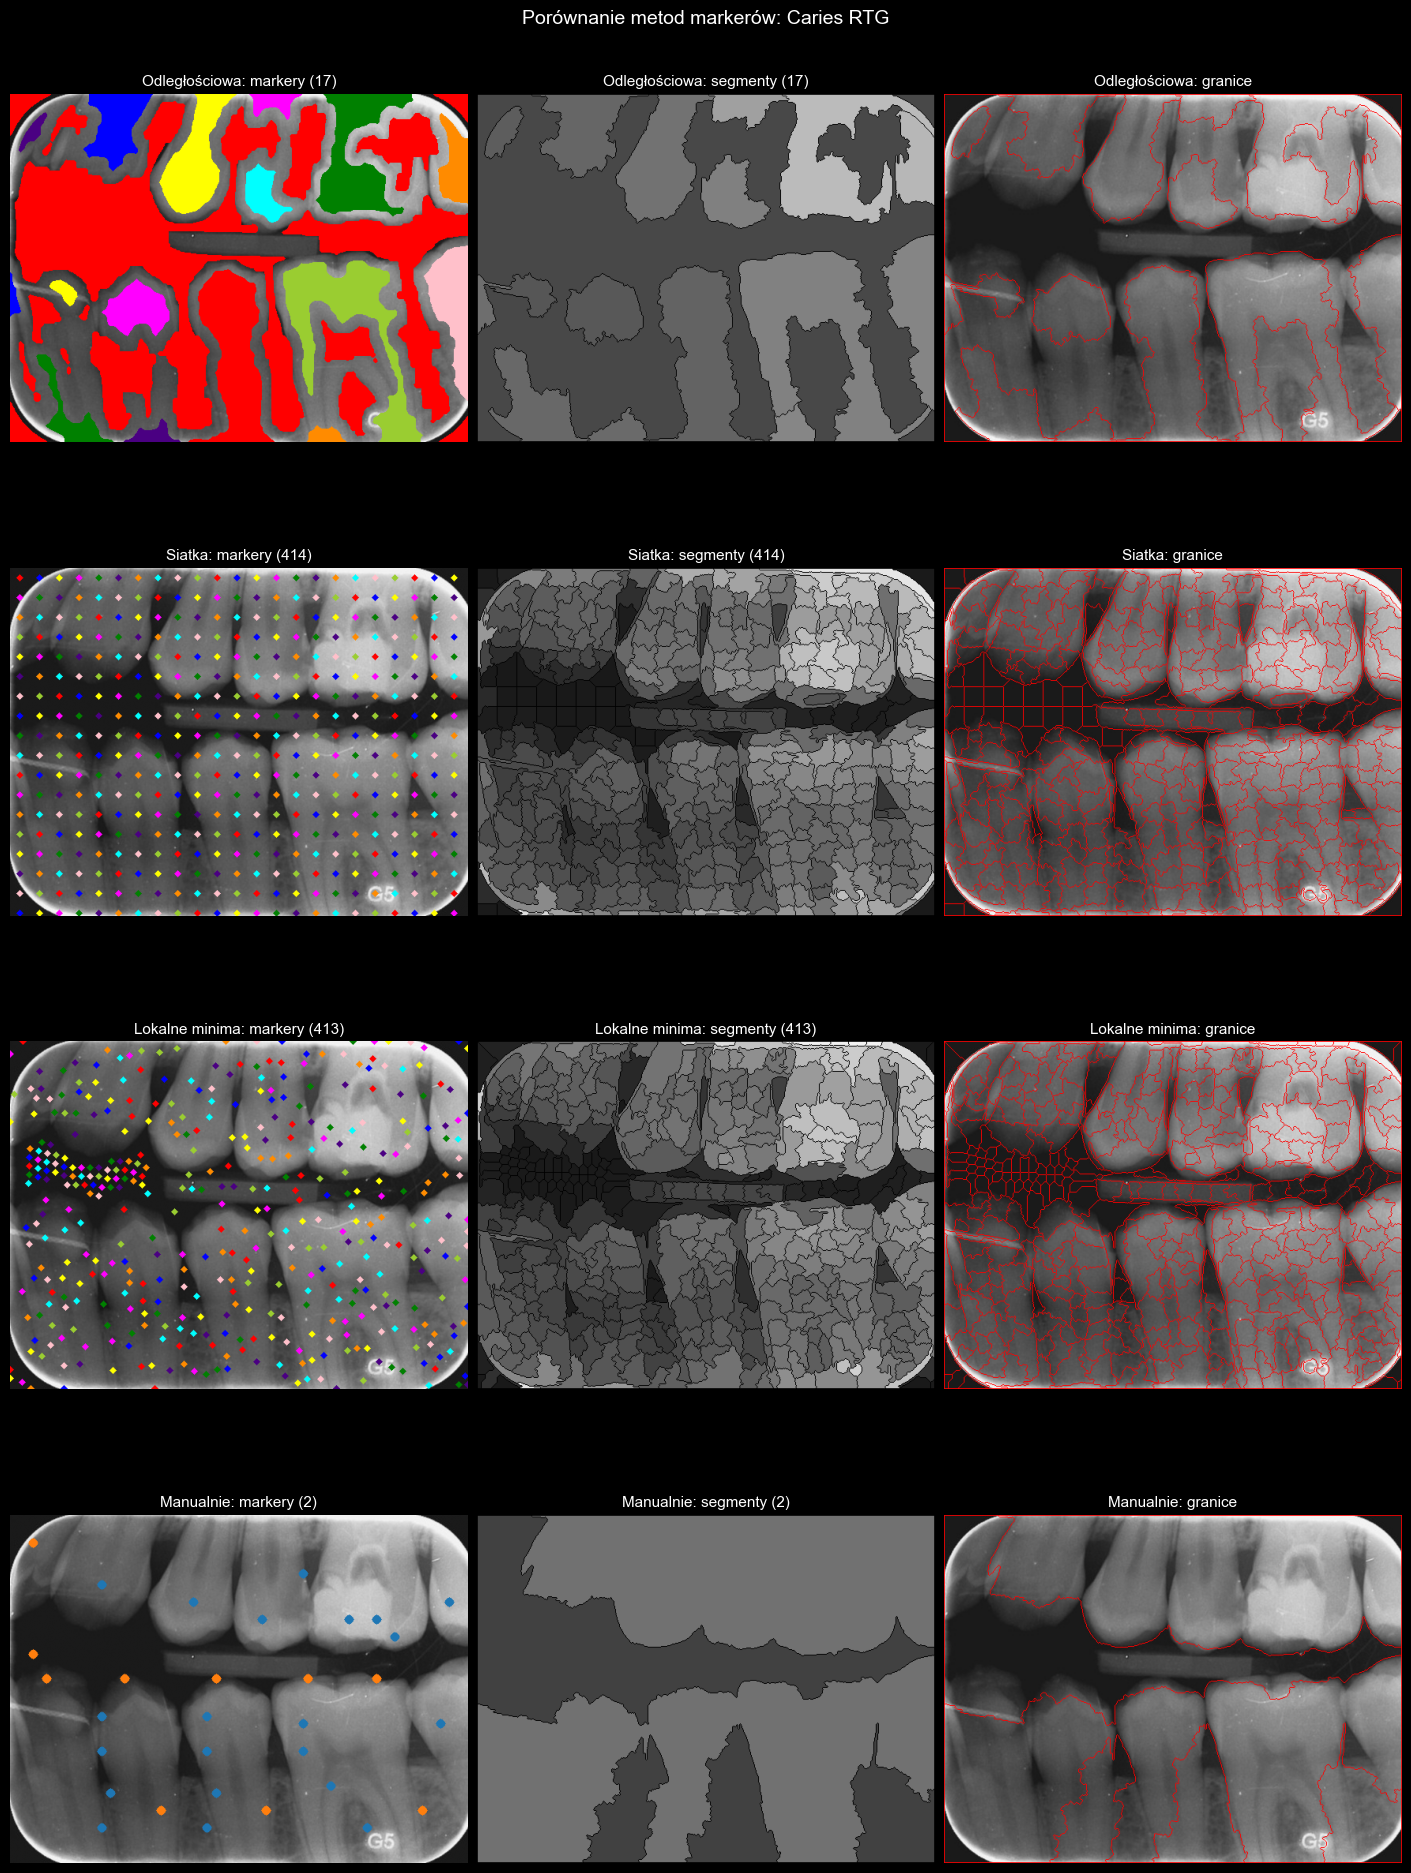

In [12]:
caries_manual = rel_points(caries, [
    [# górne korony i wypełnienie
     (0.80, 0.30), (0.84, 0.35), (0.74, 0.30),
     (0.20, 0.20), (0.40, 0.25), (0.55, 0.30), (0.64, 0.17), (0.96, 0.25),
     # dolne korony
     (0.20, 0.58), (0.20, 0.68),
     (0.43, 0.58), (0.43, 0.68),
     (0.64, 0.60), (0.64, 0.68),
     (0.94, 0.60),
     # dolne korzenie
     (0.22, 0.80), (0.20, 0.90),
     (0.45, 0.80), (0.43, 0.90),
     (0.70, 0.78), (0.78, 0.90)],

    [(0.08, 0.47), (0.25, 0.47), (0.45, 0.47), (0.65, 0.47), (0.80, 0.47),
     (0.05, 0.40), (0.05, 0.08),
     (0.33, 0.85), (0.56, 0.85), (0.90, 0.85)],
])

compare_marker_methods(caries, "Caries RTG", [
    ("Odległościowa", dict(method='distance', use_clahe=True, blur_ksize=3, alpha=0.2, min_size=500, min_marker_size=200)),
    ("Siatka",         dict(method='grid', grid_step=25, use_clahe=False, marker_radius=2)),
    ("Lokalne minima", dict(method='local_minima', use_clahe=False, blur_ksize=5, min_distance=11, marker_radius=2)),
    ("Manualnie",      dict(method='manual', use_clahe=False, manual_points=caries_manual, marker_radius=4)),
])

## 1. Odległościowa (19 markerów, 19 segmentów)

**Co wyszło**: metoda działa tu zgodnie z założeniem. Po CLAHE i Otsu maska obejmuje jasne zęby, więc rdzenie wypadają w koronach (żółty, cyjan, zielony, magenta, niebieski, pomarańczowy, różowy) i w dolnych zębach (żółty, magenta, jasnozielony, różowy). Czerwone tło to ciemna szczelina i kość. Szary pierścień wokół rdzeni to strefa „unknown”, o której decyduje watershed. 17 segmentów to tło i 16 rdzeni, czyli około 16 fragmentów zębów.

**Zalety:** pełna automatyka, mało segmentów, a wykryte ciemne struktury (szczelina, przestrzenie między zębami, trójkątne ubytki kości) mają sensowne kontury.

**Wady:** zęby i wypełnienie w ogóle nie są rozdzielone, bo są "tłem" w sensie algorytmu. Wynik odpowiada na pytanie "gdzie są ciemne dziury", a nie "gdzie jest ząb". Wypełnienie i ubytek nie wyróżniają się. Dodatkowo CLAHE wzmacnia ziarno kości i dzieli ją na kilka niepotrzebnych segmentów.

## 2. Siatka (414 markerów)

**Co wyszło:** drobne, regularne segmenty. W zębach każdy marker łapie własny kawałek tekstury, a w ciemnym tle po lewej, gdzie gradient jest płaski, powstają **regularne kwadraty**: fronty zalewania spotykają się w połowie odległości między markerami. Kontury zębów są częściowo zachowane, ale wnętrza są mocno rozdrobnione.

**Zalety:** prosta, deterministyczna, bez założeń o obrazie, nie zawodzi całkowicie. Gęstość segmentów jest przewidywalna.

**Wady:** marker nie zna treści, więc segmenty nie odpowiadają strukturom anatomicznym. Płaskie tło jest dzielone sztucznie na kwadraty, a zęby na dziesiątki kawałków. Wypełnienie jest rozbite na wiele segmentów.

## 3. Lokalne minima (413 markerów)

**Co wyszło:** markery są rozłożone nierówno. W ciemnej szczelinie po lewej tworzy się **gęsta kupka** markerów (płaski obszar ma mnóstwo prawie równych minimów gradientu), co daje drobną mozaikę. W zębach segmenty są podobnie rozdrobnione jak przy siatce. Granice częściowo trzymają się krawędzi szkliwa, a wypełnienie ma kilka własnych segmentów.

**Zalety:** markery lądują w jednorodnych obszarach, więc granice lepiej pokrywają się z krawędziami niż przy siatce, a metoda nie zakłada, czy obiekt jest jasny, czy ciemny.

**Wady:** przy `blur_ksize=5` i `min_distance=11` szum i ziarno kości generują setki minimów, więc obraz jest przesegmentowany. Płaskie obszary dają artefakty (kupka). Wcześniejsza wersja z `blur_ksize=15` i `min_distance=30` dawała ok. 60 segmentów i znacznie czytelniejszy wynik.

## 4. Manualna (2 segmenty)

**Co wyszło:** wyodrębniono zęby (jasny segment) od tła (szczelina i kość). Korony są dobrze odwzorowane, a granica szczeliny przebiega zgodnie z krawędzią szkliwa. Korzenie są częściowo poprawne, ale granica korzeń/kość jest **postrzępiona i wciska się w głąb zębów dolnych** (ciemne "palce" kości wchodzą między korzenie, a prawy korzeń jest przecięty). Górny lewy róg obrazu ma też niewielki wyciek.

**Zalety:** najczystszy i najbardziej sensowny wynik: dwa segmenty o jasnym znaczeniu. Pełna kontrola nad semantyką.

**Wady:** wymaga wiedzy i czasu, a jakość zależy od rozmieszczenia punktów. Granica korzeń/kość jest słaba z natury (podobna jasność), więc nawet dobre markery dają nierówny kontur. Nie rozdziela wypełnienia od zęba, bo oba należą do jednej grupy.

## Wnioski

1. **Markery decydują o wyniku.** Przy tym samym gradiencie dostajemy od 2 do 414 segmentów, a ich sens anatomiczny jest skrajnie różny.
2. **Metody automatyczne przesegmentowują zaszumiony RTG o niskim kontraście.** Siatka i minima dają setki segmentów, bo nie znają struktury obrazu. Zmniejszenie liczby wymaga mocniejszego wygładzenia i większego `min_distance`, kosztem drobnych struktur (ubytek, wypełnienie).
3. **Metoda odległościowa wymaga zgodności z założeniem o jasności.** Tu wykryła ciemne struktury zamiast zębów, co jest poprawne technicznie, ale odwrotne względem celu.
4. **Segmentacja interaktywna jest najlepsza dla celu "zęby kontra tło"**, ale granica korzeń/kość pozostaje trudna z powodu podobnej jasności obu struktur.
5. **Kompromis między jednolitością a zwięzłością**, jak przy SLIC: im więcej markerów, tym jednolitsze segmenty, ale mniej zwięzła reprezentacja.
6. **CLAHE** pomaga progowaniu w metodzie odległościowej, ale wzmacnia ziarno kości, dlatego w pozostałych metodach lepiej go wyłączyć (tu tak zrobiono).

---

#### Zadanie dodatkowe (dla chętnych, bez oceny)

Dla obrazu `tabby` wykonaj post-processing wybranej metody segmentacji by uzyskać dwa jednorodne obszary: jeden zawierający wyłącznie kota, drugi zawierający wyłącznie tło.

Można to zadanie potraktować jako binaryzację na poziomie superpikseli i zrealizować je za pomocą progowania. 
Można też potraktować je jako klasteryzację superpikseli i wykorzystać np. [`cv2.kmeans`](https://docs.opencv.org/4.x/d5/d38/group__core__cluster.html#ga9a34dc06c6ec9460e90860f15bcd2f88).  
Niezależnie od wybranej ścieżki, konieczne będzie:
1. dobranie odpowiednich (czyli jakich?) parametrów algorytmu segmentacji,
2. opisanie każdego z superpikseli za pomocą jakiejś *cechy/cech* (jakich?), opisującej semantykę rejonów, tak aby na tej podstawie dokonać klasyfikacji.

In [13]:
# zacznij od przygotowania macierzy wejściowej (data) reprezentującej superpiksele jako punkty danych